# Week5_ex1_analysis — IEC 60909 short-circuit currents vs. the classical method

Deep dive. PowerWorld and the textbook use the classical method: a pre-fault voltage from the power flow and unmodified impedances,

$$I_F = \frac{V_F}{Z_{kk}}, \qquad V_F = 1.05\ \text{pu}$$

pandapower's `calc_sc` follows IEC 60909, which scales the source voltage by $c_{max} = 1.1$ and corrects generator and network transformer impedances:

$$I''_k = \frac{c\,U_n}{\sqrt{3}\,|Z_k|}, \qquad K_G = \frac{U_n}{U_{rG}}\,\frac{c_{max}}{1 + x''_d \sin\varphi_{rG}}, \qquad K_T = 0.95\,\frac{c_{max}}{1 + 0.6\,x_T}$$

This notebook measures how far `calc_sc` is from PowerWorld on the Example 8.5 system and explains the gap.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.shortcircuit as sc
from case5 import BUSES, S_BASE, V_PREFAULT, GENS, TRAFOS, LINES, build_case

# 1. calc_sc triggers a pandas downcasting FutureWarning inside pandapower's branch builder;
#    it does not affect the results and its message prints the local install path
warnings.filterwarnings("ignore", category=FutureWarning)

# 2. PowerWorld three-phase fault currents (pre-fault profile = solved power flow)
i_pw = pd.Series([37.53623, 18.43659, 57.55555, 44.45645, 35.62404], index=BUSES)

def ikss_pu(net):
    # 3. kA -> pu on each bus's own base current
    return net.res_bus_sc.ikss_ka / (S_BASE / (np.sqrt(3) * net.bus.vn_kv))

# 4. calc_sc defaults (IEC max case) and the pre-fault voltage option
n_iec = build_case()
sc.calc_sc(n_iec, case="max", fault="3ph")
n_pfv = build_case()
pp.runpp(n_pfv, numba=False)
sc.calc_sc(n_pfv, case="max", fault="3ph", use_pre_fault_voltage=True)

meas = pd.DataFrame({"PowerWorld [pu]": i_pw,
                     "calc_sc IEC max [pu]": ikss_pu(n_iec),
                     "calc_sc pre-fault V [pu]": ikss_pu(n_pfv)})
meas["IEC err [%]"] = (meas.iloc[:, 1] / i_pw - 1) * 100
meas["Pre-fault V err [%]"] = (meas.iloc[:, 2] / i_pw - 1) * 100
meas.index.name = "Faulted bus"
meas.round(3)

,PowerWorld [pu],calc_sc IEC max [pu],calc_sc pre-fault V [pu],IEC err [%],Pre-fault V err [%]
Faulted bus,,,,,
1,37.536,37.048,35.551,-1.301,-5.289
2,18.437,18.824,18.044,2.102,-2.131
3,57.556,55.882,53.450,-2.909,-7.133
4,44.456,43.729,42.165,-1.635,-5.154
5,35.624,35.487,34.149,-0.385,-4.142


## Hypothesis 1

The gap comes only from the voltage factor: `calc_sc` drives the fault with $c = 1.1$ instead of 1.05, so every current should be $1.1/1.05 - 1 = +4.76\%$ higher.

In [2]:
# 5. Prediction if only the voltage factor differed
h1 = pd.DataFrame({"Predicted err [%]": (1.1 / V_PREFAULT - 1) * 100,
                   "Measured IEC err [%]": meas["IEC err [%]"]})
h1.round(3)

,Predicted err [%],Measured IEC err [%]
Faulted bus,,
1,4.762,-1.301
2,4.762,2.102
3,4.762,-2.909
4,4.762,-1.635
5,4.762,-0.385


**Verdict: rejected.** The measured errors range from −2.9% to +2.1% and change sign between buses, so something besides the voltage factor is at work.

## Hypothesis 2

`calc_sc` also applies the IEC impedance correction factors: $K_G$ to each generator's $x''_d$ and $K_T$ to each network transformer. Rebuilding Zbus by hand with $c = 1.1$ and both factors should reproduce `calc_sc` exactly.

In [3]:
def fault_currents(v_source, kg=(1.0, 1.0), kt=(1.0, 1.0)):
    # 6. Hand-built Zbus with optional correction factors; returns |I_F| at every bus
    idx = {b: i for i, b in enumerate(BUSES)}
    y = np.zeros((5, 5), complex)
    branches = [(hv, lv, x * k) for (hv, lv, x), k in zip(TRAFOS, kt)] + LINES
    for f, t, x in branches:
        a, b, yb = idx[f], idx[t], 1 / (1j * x)
        y[a, a] += yb; y[b, b] += yb; y[a, b] -= yb; y[b, a] -= yb
    for (b, xdd), k in zip(GENS, kg):
        y[idx[b], idx[b]] += 1 / (1j * xdd * k)
    return pd.Series(v_source / np.abs(np.diag(np.linalg.inv(y))), index=BUSES)

# 7. Correction factors for c_max = 1.1, cos(phi_rG) = 0.85, U_n = U_rG
C_MAX, SIN_PHI = 1.1, np.sqrt(1 - 0.85 ** 2)
KG = tuple(C_MAX / (1 + xdd * SIN_PHI) for _, xdd in GENS)
KT = tuple(0.95 * C_MAX / (1 + 0.6 * x) for _, _, x in TRAFOS)

h2 = pd.DataFrame({"c=1.1, no K [pu]": fault_currents(C_MAX),
                   "c=1.1, K_G + K_T [pu]": fault_currents(C_MAX, KG, KT),
                   "calc_sc IEC max [pu]": meas["calc_sc IEC max [pu]"]})
h2["Diff [pu]"] = (h2.iloc[:, 1] - h2.iloc[:, 2]).abs()
assert h2["Diff [pu]"].max() < 1e-6
factors = pd.DataFrame({"Factor": ["K_G (G1)", "K_G (G3)", "K_T (T 5-1)", "K_T (T 4-3)"],
                        "Value": KG + KT})
display(factors.round(4))
h2.round(4)

,Factor,Value
0,K_G (G1),1.0745
1,K_G (G3),1.0871
2,K_T (T 5-1),1.0326
3,K_T (T 4-3),1.0388


,"c=1.1, no K [pu]","c=1.1, K_G + K_T [pu]",calc_sc IEC max [pu],Diff [pu]
1,39.3237,37.0480,37.0480,0.0
2,19.3145,18.8241,18.8241,0.0
3,60.2963,55.8815,55.8815,0.0
4,46.5734,43.7294,43.7294,0.0
5,37.3204,35.4871,35.4871,0.0


**Verdict: accepted.** With $c = 1.1$, $K_G$ and $K_T$ the hand calculation matches `calc_sc` to better than $10^{-6}$ pu. $K_G$ (1.07–1.09) and $K_T$ (≈1.03) raise the impedances and cancel most of the voltage factor. Buses next to a generator (1 and 3) feel $K_G$ directly and end up below PowerWorld; bus 2, electrically far from both machines, keeps more of the +4.76% and ends up above it.

In [4]:
# 8. K_G depends on the rated power factor, which the PowerWorld case does not carry
sens = {}
for pf in [0.80, 0.85, 0.90, 1.00]:
    n = build_case(gen_cos_phi=pf)
    sc.calc_sc(n, case="max", fault="3ph")
    sens[f"Err at cos_phi={pf:.2f} [%]"] = (ikss_pu(n) / i_pw - 1) * 100
sens = pd.DataFrame(sens)
sens.index.name = "Faulted bus"
sens.round(3)

,Err at cos_phi=0.80 [%],Err at cos_phi=0.85 [%],Err at cos_phi=0.90 [%],Err at cos_phi=1.00 [%]
Faulted bus,,,,
1,-1.086,-1.301,-1.567,-2.847
2,2.169,2.102,2.018,1.610
3,-2.752,-2.909,-3.103,-4.037
4,-1.507,-1.635,-1.795,-2.564
5,-0.245,-0.385,-0.558,-1.397


## Hypothesis 3

`use_pre_fault_voltage=True` switches `calc_sc` to the classical method, so it should match PowerWorld.

In [5]:
# 9. Candidate explanations for the pre-fault voltage option
h3 = pd.DataFrame({"PowerWorld [pu]": i_pw,
                   "V=1.05, no K [pu]": fault_currents(V_PREFAULT),
                   "V=1.05, K_G only [pu]": fault_currents(V_PREFAULT, KG),
                   "V=1.05, K_G + K_T [pu]": fault_currents(V_PREFAULT, KG, KT),
                   "calc_sc pre-fault V [pu]": meas["calc_sc pre-fault V [pu]"]})
h3["Diff (K_G only) [pu]"] = (h3["V=1.05, K_G only [pu]"] - h3["calc_sc pre-fault V [pu]"]).abs()
assert h3["Diff (K_G only) [pu]"].max() < 1e-6
h3.round(4)

,PowerWorld [pu],"V=1.05, no K [pu]","V=1.05, K_G only [pu]","V=1.05, K_G + K_T [pu]",calc_sc pre-fault V [pu],Diff (K_G only) [pu]
1,37.5362,37.5362,35.5510,35.3640,35.5510,0.0
2,18.4366,18.4366,18.0437,17.9685,18.0437,0.0
3,57.5556,57.5556,53.4500,53.3415,53.4500,0.0
4,44.4564,44.4565,42.1650,41.7417,42.1650,0.0
5,35.6240,35.6240,34.1486,33.8740,34.1486,0.0


**Verdict: rejected.** The option does use the 1.05 pu pre-fault voltage, but it still applies $K_G$ (only $K_T$ is dropped). The result sits 2.1–7.1% *below* PowerWorld — the unsafe direction for breaker duty.

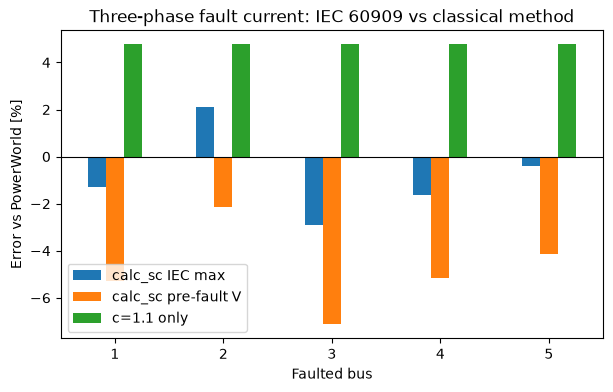

In [6]:
# 10. Error of each method against PowerWorld
err = pd.DataFrame({"calc_sc IEC max": meas["IEC err [%]"],
                    "calc_sc pre-fault V": meas["Pre-fault V err [%]"],
                    "c=1.1 only": h1["Predicted err [%]"]})
ax = err.plot.bar(figsize=(7, 4), rot=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Faulted bus")
ax.set_ylabel("Error vs PowerWorld [%]")
ax.set_title("Three-phase fault current: IEC 60909 vs classical method")
plt.savefig("Images/Week5_ex1_iec_vs_classical_fault_current.png", dpi=150, bbox_inches="tight")
plt.show()

## Final conclusion

- The classical method (Ybus with $x''_d$, $V_F$ from the power flow) reproduces PowerWorld exactly; `calc_sc` cannot be configured to do the same.
- `calc_sc` defaults = $c_{max} = 1.1$ **plus** $K_G$ and $K_T$. The net effect is not a uniform +4.76%: here it ranges from −2.9% to +2.1% depending on how close the bus is to a generator.
- `use_pre_fault_voltage=True` is not the classical method. It keeps $K_G$ and underestimates the current by up to 7.1%.
- $K_G$ depends on the generator's rated power factor and $K_T$ on the transformer's own rating, so `calc_sc` results need realistic `cos_phi` and `sn_mva` values, not system-base placeholders.

**Rules for the project:** use a hand-built Zbus when checking against PowerWorld or the textbook; use `calc_sc` with default settings (IEC max) for breaker duty and equipment checks; do not use `use_pre_fault_voltage`.